*Mathematical Foundations of Robotics · Chapter 1 — Introduction, Joints and Degrees of Freedom*

# 1.4 Configuration Space

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kushagrathisside/Robotics-Guide/blob/main/MFoR/01-introduction-and-degrees-of-freedom/1.4-configuration-space.ipynb)

The **configuration space** (C-space) of a robot is the set of all its configurations. Its *dimension* is the number of
degrees of freedom, but its *shape* — whether angles wrap around, whether it has holes or several pieces — matters just as
much: it decides how motions can be interpolated, which coordinates can be used without singularities, and which
configurations can be reached from which. This notebook describes the shape of the configuration spaces met in
robotics (circle, torus, the rotation group, the C-space of a four-bar), the difference between **explicit** and **implicit**
descriptions, and the two kinds of constraint — **holonomic** and **non-holonomic** — with a car that can park sideways although it cannot move sideways.

| | |
|:--|:--|
| **Primary reading** | Craig, 3rd ed., Ch. 1 and §2.8 (orientation as a point of a three-dimensional set) — the topic is treated most fully by Lynch & Park |
| **Parallel reading** | Lynch & Park, *Modern Robotics*, §2.3–2.4 (topology and representation of C-space; configuration and velocity constraints) · Siciliano et al., Ch. 1 and §2.2 · Spong et al., Ch. 2 |
| **Lectures** | [Modern Robotics — 2.3.1 C-space topology](https://www.youtube.com/watch?v=FyLNR3edOds) · [Modern Robotics — 2.3.2 C-space representation](https://www.youtube.com/watch?v=PPgJPjCUIXU) · [Modern Robotics — 2.4 Configuration and velocity constraints](https://www.youtube.com/watch?v=A14ArEZ47LE) |
| **Prerequisites** | [1.3 Degrees of Freedom and Grübler's Formula](1.3-degrees-of-freedom-and-grublers-formula.ipynb); Chapter 2 (rotation matrices) helps for Section 4 |
| **Study time** | about 3 hours, including the exercises |

## Learning objectives

After working through this notebook you should be able to:

1. define configuration and configuration space, and give the dimension and topology of the C-space of a pendulum, a planar 2R arm, a planar rigid body and a spatial rigid body;
2. compute distances and interpolate on a circle and a torus, taking the wrap-around into account;
3. contrast **explicit** (minimal) and **implicit** (constrained) representations, and compute the dimension of an implicitly defined space as $n - \operatorname{rank}$;
4. describe $SO(3)$ as a ball with antipodal boundary points identified, and explain why unit quaternions double-cover it;
5. find the C-space of the four-bar linkage as a curve in a torus and read off whether its two assembly modes are connected;
6. distinguish holonomic from non-holonomic constraints, test integrability with a Lie bracket, and simulate the parking manoeuvre of a car.

## Contents

1. [Configurations and configuration space](#1.-Configurations-and-configuration-space)
2. [Topology: the circle and the torus](#2.-Topology:-the-circle-and-the-torus)
3. [Explicit and implicit representations](#3.-Explicit-and-implicit-representations)
4. [The topology of rotations](#4.-The-topology-of-rotations)
5. [C-space of closed chains and of real robots](#5.-C-space-of-closed-chains-and-of-real-robots)
6. [Holonomic and non-holonomic constraints](#6.-Holonomic-and-non-holonomic-constraints)
7. [Worked examples](#7.-Worked-examples)
8. [Summary, common mistakes and exercises](#8.-Summary)

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────
# Makes the shared `rgkit` package importable, both locally and on Google Colab.
import sys, pathlib, subprocess
if "google.colab" in sys.modules:                                   # Colab
    if not pathlib.Path("Robotics-Guide").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/kushagrathisside/Robotics-Guide.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mujoco", "mediapy"], check=True)
    sys.path.insert(0, "Robotics-Guide")
else:                                                               # local Jupyter
    root = pathlib.Path.cwd().resolve()
    while not (root / "rgkit").is_dir() and root != root.parent:
        root = root.parent
    sys.path.insert(0, str(root))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown
import ipywidgets as widgets

from rgkit import setup_notebook, interact
from rgkit.plotting import (new_axes3d, draw_frame, draw_vector, draw_point, draw_box,
                            draw_frame_2d, draw_vector_2d, matrix_to_latex, AXIS_COLORS)
from rgkit.animation import animate, filmstrip

setup_notebook()
deg = np.deg2rad          # degrees -> radians

from rgkit import mujoco_utils as mju, robots, joint_census as jc, mechanisms as mech, cspace as cs, transforms as tf
import mujoco

## 1. Configurations and configuration space

A **configuration** of a robot is a complete specification of the position of every point of it; the **configuration space** (C-space)
$\mathcal C$ is the set of all configurations. Because links are rigid, a configuration is determined by a few numbers, and
$\dim\mathcal C$ equals the degrees of freedom of Notebook 1.3. The table lists the C-spaces used most often. Here $S^1$ is the circle
(one angle), $\mathbb R$ the line, $SO(2)$ and $SO(3)$ the planar and spatial rotations, and $\times$ the *product* of spaces: a
configuration is a pair (or a list) of configurations of the factors.

| System | C-space | Dimension |
|:--|:--|:-:|
| bead on a wire; a prismatic joint with limits | an interval $[a,b]\subset\mathbb R$ | 1 |
| a pendulum; a revolute joint | circle $S^1$ | 1 |
| a planar two-link arm with no joint limits | torus $T^2 = S^1\times S^1$ | 2 |
| an $n$R arm (unlimited joints) | torus $T^n$ | $n$ |
| a point on a sphere (spherical pendulum) | sphere $S^2$ | 2 |
| a rigid body in the plane | $\mathbb R^2\times S^1 = SE(2)$ | 3 |
| a rigid body in space | $\mathbb R^3\times SO(3) = SE(3)$ | 6 |
| a mobile manipulator: a rigid body carrying an $n$-joint arm | $SE(2)\times T^n$ (planar base) | $3+n$ |

The dimension counts the *local* coordinates. The shape says more: for example, the C-space of the 2R arm is a **torus**, not the plane
$\mathbb R^2$, because $\theta_1$ and $\theta_1+2\pi$ describe the same configuration. A joint with *limits* (like most real joints) has
an interval instead of a circle and its C-space is a **box** — a subset of the torus.

## 2. Topology: the circle and the torus

Topology is the study of shape up to stretching and bending. Two facts matter in robotics.

**Angles live on a circle.** The *difference* between two angles is not $\theta_2 - \theta_1$ but the shorter way round the circle,
$\operatorname{wrap}(\theta_2-\theta_1)\in(-\pi,\pi]$. A controller that subtracts raw angles can make a joint turn 340° the long way
instead of 20° the short way. On a torus the same is done coordinate by coordinate: the geodesic distance between two configurations
of an $n$R arm is $\lVert \operatorname{wrap}(\mathbf q_2-\mathbf q_1)\rVert$, and the shortest interpolation moves each joint along its own short arc.

**The torus can be cut open.** Cutting the torus along two circles gives a square whose opposite edges are *identified* — leaving through the right edge means re-entering on the left. A straight
line of constant joint velocity is a straight line on this square that wraps around.

naive difference of the angles  : [-340.  320.] deg
shortest signed difference      : [ 20. -40.] deg
geodesic distance on the torus  : 44.72 deg  vs naive 466.9 deg
shortest-path midpoint (deg)    : [0. 0.]


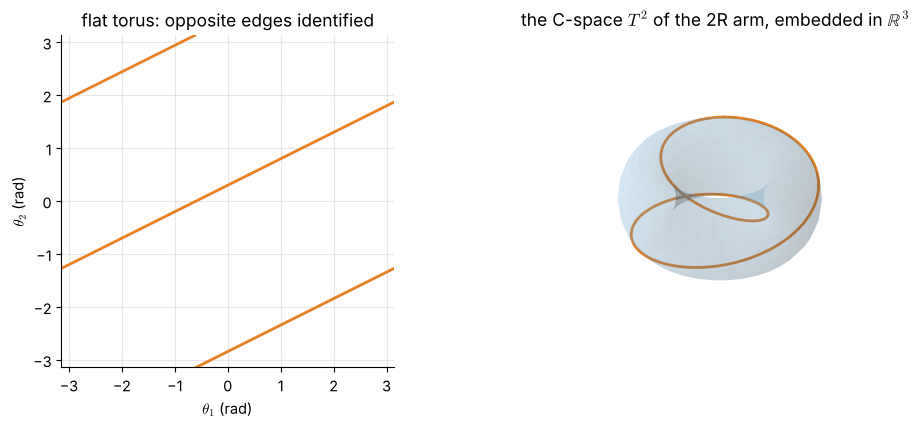

In [2]:
q1, q2 = np.radians([350.0, 20.0]), np.radians([10.0, 340.0])
print("naive difference of the angles  :", np.degrees(q2 - q1).round(1), "deg")
print("shortest signed difference      :", np.degrees(cs.angle_diff(q1, q2)).round(1), "deg")
print("geodesic distance on the torus  :", round(np.degrees(cs.torus_distance(q1, q2)), 2), "deg  vs naive", round(np.degrees(np.linalg.norm(q2 - q1)), 1), "deg")
mid = cs.torus_interpolate(q1, q2, 0.5); print("shortest-path midpoint (deg)    :", np.degrees(mid).round(1))

# a constant-velocity joint motion of the 2R arm: a line on the flat torus and a curve on the 3-D torus
t = np.linspace(0, 1, 400)
th1, th2 = 0.4 + 2 * np.pi * 2 * t, 0.5 + 2 * np.pi * 1 * t
fig = plt.figure(figsize=(10.6, 4.4))
ax = fig.add_subplot(1, 2, 1)
w1, w2 = cs.wrap_to_pi(th1), cs.wrap_to_pi(th2)
jump = (np.abs(np.diff(w1)) > np.pi) | (np.abs(np.diff(w2)) > np.pi)
for seg in np.split(np.arange(len(t)), np.where(jump)[0] + 1):
    ax.plot(w1[seg], w2[seg], "-", color="#e67e22", lw=2)
ax.set_xlim(-np.pi, np.pi); ax.set_ylim(-np.pi, np.pi); ax.set_aspect("equal")
ax.set_xlabel(r"$\theta_1$ (rad)"); ax.set_ylabel(r"$\theta_2$ (rad)"); ax.set_title("flat torus: opposite edges identified")
ax3 = fig.add_subplot(1, 2, 2, projection="3d")
u, v = np.meshgrid(np.linspace(0, 2 * np.pi, 40), np.linspace(0, 2 * np.pi, 20))
R_, r_ = 2.0, 0.8
ax3.plot_surface((R_ + r_ * np.cos(v)) * np.cos(u), (R_ + r_ * np.cos(v)) * np.sin(u), r_ * np.sin(v), alpha=0.18, color="#85c1e9", linewidth=0)
ax3.plot((R_ + r_ * np.cos(th2)) * np.cos(th1), (R_ + r_ * np.cos(th2)) * np.sin(th1), r_ * np.sin(th2), "-", color="#e67e22", lw=2)
ax3.set_box_aspect((1, 1, 0.4)); ax3.set_axis_off(); ax3.view_init(elev=35, azim=-60); ax3.set_title(r"the C-space $T^2$ of the 2R arm, embedded in $\mathbb{R}^3$")
plt.tight_layout(); plt.show()

The figure shows one motion of the 2R arm in which $\theta_1$ turns twice while $\theta_2$ turns once. On the flat square the path is cut into five
pieces; on the torus it is a single closed curve winding twice around the long way and once around the short way. The dimension of $T^2$ is two,
but a *single* chart of $\mathbb R^2$ cannot describe it without a seam: this is why code that stores angles must decide where to cut (at $\pm\pi$ or at $0$ and $2\pi$) and treat
differences with `wrap`. Notebook 1.5 shows how the torus is mapped onto the workspace of the arm.

## 3. Explicit and implicit representations

A C-space can be described in two ways.

* **Explicit (minimal)**: use exactly $\dim\mathcal C$ coordinates, for example the joint angles $(\theta_1,\dots,\theta_n)$. This is compact, but
  an explicit chart of a curved space always has *singular* places where it fails — like longitude at the poles of the globe.
* **Implicit**: use more coordinates than the dimension, tied together by constraint equations. A point of the circle $S^1$ is $(x,y)$ with $x^2+y^2=1$
  (2 numbers, 1 constraint); a rotation is a matrix $R$ with $R^{\mathsf T}R=I$ (9 numbers, 6 constraints) or a unit quaternion (4 numbers, 1 constraint).
  Implicit descriptions have **no singularities** but need constraint maintenance (re-normalisation).

The dimension of an implicit space $\{x\in\mathbb R^n:\ g(x)=0\}$ is $n - \operatorname{rank}(\partial g/\partial x)$ — formula (1.5) of Notebook 1.3.
The cell checks the counts for $S^1$, $S^2$, $SO(3)$ and the unit quaternions, and shows that the **explicit** Euler-angle chart of $SO(3)$ loses rank at the
gimbal-lock angle $\beta=90^\circ$ while the implicit matrix description does not.

In [3]:
rng = np.random.default_rng(2)
R0 = tf.rot_axis_angle(rng.normal(size=3), 0.7)
dims = {"circle  S^1  {x^2+y^2=1}": cs.manifold_dimension(lambda x: np.array([x @ x - 1]), np.array([0.6, 0.8])),
        "sphere  S^2  {|x|^2=1}": cs.manifold_dimension(lambda x: np.array([x @ x - 1]), np.array([0.6, 0.0, 0.8])),
        "SO(3)  {R^T R = I}  (9 numbers)": cs.manifold_dimension(cs.so3_constraint, R0.ravel()),
        "unit quaternions  {|q|^2=1}  (4 numbers)": cs.manifold_dimension(lambda q: np.array([q @ q - 1]), tf.quat_from_axis_angle([1, 2, 3], 0.7))}
for k, v in dims.items(): print(f"{k:42s} dimension = {v}")
assert list(dims.values()) == [1, 2, 3, 3]

# the explicit chart: Z-Y-X Euler angles -> rotation matrix; Jacobian of the 9 entries w.r.t. the 3 angles
def chart(e): return tf.euler_zyx_to_rot(*e).ravel()
def jac_rank(e, h=1e-6):
    J = np.array([(chart(e + h * np.eye(3)[k]) - chart(e - h * np.eye(3)[k])) / (2 * h) for k in range(3)]).T
    return np.linalg.matrix_rank(J, tol=1e-6)
for beta in [0.3, 1.2, np.pi / 2 - 1e-3, np.pi / 2]:
    print(f"Euler angles (alpha, beta, gamma) = (0.4, {np.degrees(beta):7.3f}°, 0.9): rank of dR/d(angles) = {jac_rank(np.array([0.4, beta, 0.9]))}")
assert jac_rank(np.array([0.4, 0.3, 0.9])) == 3 and jac_rank(np.array([0.4, np.pi / 2, 0.9])) == 2

circle  S^1  {x^2+y^2=1}                   dimension = 1
sphere  S^2  {|x|^2=1}                     dimension = 2
SO(3)  {R^T R = I}  (9 numbers)            dimension = 3
unit quaternions  {|q|^2=1}  (4 numbers)   dimension = 3
Euler angles (alpha, beta, gamma) = (0.4,  17.189°, 0.9): rank of dR/d(angles) = 3
Euler angles (alpha, beta, gamma) = (0.4,  68.755°, 0.9): rank of dR/d(angles) = 3
Euler angles (alpha, beta, gamma) = (0.4,  89.943°, 0.9): rank of dR/d(angles) = 3
Euler angles (alpha, beta, gamma) = (0.4,  90.000°, 0.9): rank of dR/d(angles) = 2


At $\beta = 90^\circ$ the Jacobian has rank 2: the three angles produce only two independent rotation directions, so one rotational freedom is *lost* —
**gimbal lock** (Chapter 2, Notebook 2.4). Representing a rotation by the matrix or the quaternion avoids it, at the price of 6 or 1 constraints.
The dimensions of $S^1$, $S^2$, $SO(3)$ and of the unit quaternions agree with $n - \text{rank}$.

## 4. The topology of rotations

The set $SO(3)$ is three-dimensional, but it is **not** $\mathbb R^3$ and not a sphere. Two descriptions make its shape concrete.

**The ball of rotation vectors.** Every rotation is a turn by an angle $\theta\in[0,\pi]$ about a unit axis $\hat{\mathbf n}$; assign it the vector
$\theta\hat{\mathbf n}$. These vectors fill a ball of radius $\pi$. A half turn about $\hat{\mathbf n}$ equals a half turn about $-\hat{\mathbf n}$, so
**antipodal points of the boundary sphere are the same rotation**: gluing them gives $SO(3)$. A path that leaves the ball through the boundary immediately re-enters at the opposite point.

**The sphere of unit quaternions.** The unit quaternions form a 3-sphere $S^3$ (the 3-dimensional surface of the 4-ball) and $q$ and $-q$ give the same rotation, so
$S^3$ **double covers** $SO(3)$: $SO(3)\cong S^3/\{\pm1\}$. A rotation of $360^\circ$ returns the matrix to its start but takes $q$ to $-q$; a rotation of $720^\circ$ returns the quaternion as well.
The consequence is that a loop of rotations through one full turn **cannot be shrunk to a point** in $SO(3)$, while a loop of two full turns can.
The figure shows both pictures for a rotation about a fixed axis from $0$ to $360^\circ$.

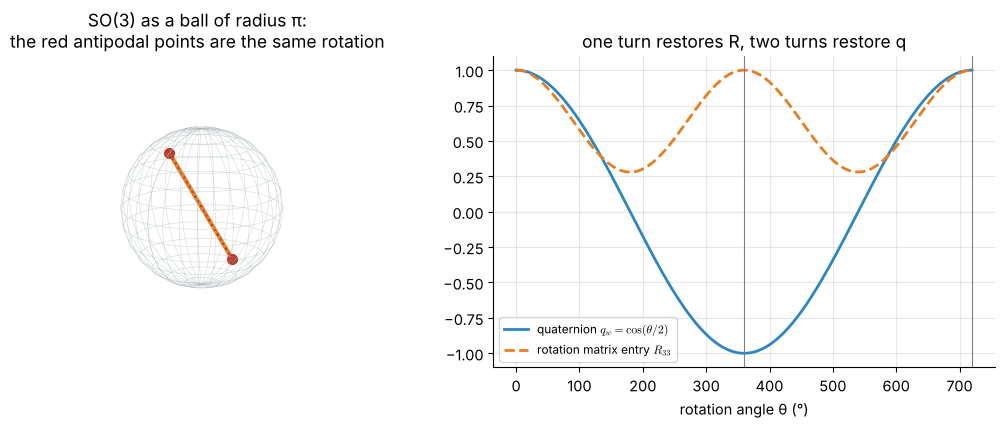

after 360°: R == I: True | q = [-1.  0.  0.  0.] (= -[1,0,0,0])  | after 720°: q = [ 1. -0. -0. -0.]
half turns about n and -n: True


In [4]:
n = np.array([0.6, 0.0, 0.8]); ths = np.linspace(0.0, 2 * np.pi, 361)
ball = np.array([cs.rotvec_ball(tf.rot_axis_angle(n, t)) for t in ths])
quats = np.array([tf.quat_from_axis_angle(n, t) for t in np.linspace(0.0, 4 * np.pi, 721)])
fig = plt.figure(figsize=(10.8, 4.4))
ax = fig.add_subplot(1, 2, 1, projection="3d")
u, v = np.meshgrid(np.linspace(0, 2 * np.pi, 30), np.linspace(0, np.pi, 15))
ax.plot_wireframe(np.pi * np.cos(u) * np.sin(v), np.pi * np.sin(u) * np.sin(v), np.pi * np.cos(v), color="#aab7b8", lw=0.4, alpha=0.5)
jumpb = np.where(np.linalg.norm(np.diff(ball, axis=0), axis=1) > 1.0)[0]
for seg in np.split(np.arange(len(ths)), jumpb + 1):
    ax.plot(*ball[seg].T, "-", color="#e67e22", lw=3)
ax.scatter(*(np.pi * n), color="#c0392b", s=50); ax.scatter(*(-np.pi * n), color="#c0392b", s=50)
ax.plot(*np.array([np.pi * n, -np.pi * n]).T, ":", color="#c0392b", lw=1.5)
ax.set_box_aspect((1, 1, 1)); ax.set_axis_off(); ax.view_init(elev=15, azim=40)
ax.set_title("SO(3) as a ball of radius π:\nthe red antipodal points are the same rotation")
ax2 = fig.add_subplot(1, 2, 2)
tt = np.degrees(np.linspace(0.0, 4 * np.pi, 721))
ax2.plot(tt, quats[:, 0], color="#2e86c1", lw=2, label=r"quaternion $q_w=\cos(\theta/2)$")
Rxx = np.array([tf.rot_axis_angle(n, t)[2, 2] for t in np.linspace(0.0, 4 * np.pi, 721)])
ax2.plot(tt, Rxx, "--", color="#e67e22", lw=2, label=r"rotation matrix entry $R_{33}$")
ax2.axvline(360, color="grey", lw=0.8); ax2.axvline(720, color="grey", lw=0.8)
ax2.set_xlabel("rotation angle θ (°)"); ax2.set_title("one turn restores R, two turns restore q"); ax2.legend(fontsize=8.5, loc="lower left")
plt.tight_layout(); plt.show()
R360, q360 = tf.rot_axis_angle(n, 2 * np.pi), tf.quat_from_axis_angle(n, 2 * np.pi)
print("after 360°: R == I:", np.allclose(R360, np.eye(3)), "| q =", q360.round(3), "(= -[1,0,0,0])  | after 720°: q =", tf.quat_from_axis_angle(n, 4 * np.pi).round(3))
print("half turns about n and -n:", np.allclose(cs.rotation_from_ball(np.pi * n), cs.rotation_from_ball(-np.pi * n)))
assert np.allclose(R360, np.eye(3)) and np.allclose(q360, [-1, 0, 0, 0])

## 5. C-space of closed chains and of real robots

**The four-bar.** Its joint angles $(\theta_2,\theta_3,\theta_4)$ (crank, coupler, rocker) live in the torus $T^3$, but only configurations satisfying the loop-closure
equations are allowed. That is an **implicit** description, and its dimension is $3 - 2 = 1$: the C-space is a *curve* in $T^3$. Projected onto the $(\theta_2,\theta_4)$ torus
it is easy to draw. For each crank angle the loop has up to two assemblies (the *branches*), and the topology of the curve answers the practical question: *can the linkage be
moved from one assembly to the other without taking it apart?* The two examples differ in **Grashof's condition** (shortest + longest $\le$ sum of the other two):

* a **crank-rocker** (the shortest link is the crank; every crank angle can be assembled) has a C-space of **two separate closed curves**, one per branch — the branches are never connected;
* a **non-Grashof** four-bar has no fully rotating link; the crank angle is limited and the two branches join at the limits, giving **one** closed curve.

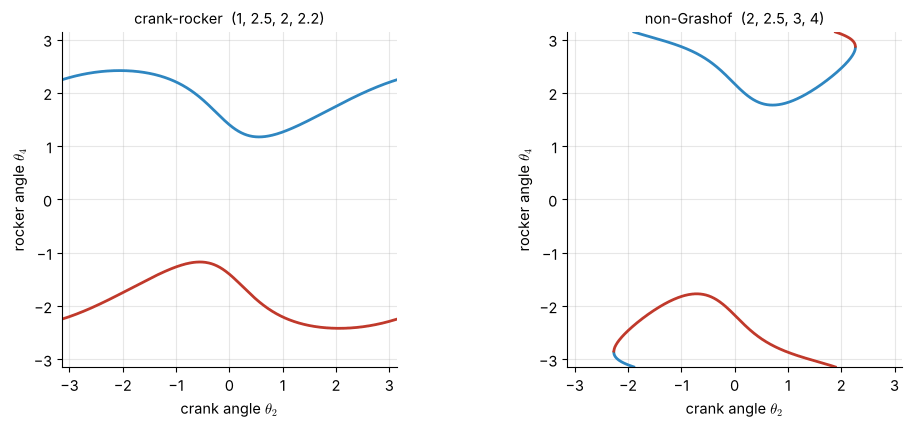

crank-rocker  (1, 2.5, 2, 2.2): crank angle range assembled 360° (branch +) / 360° (branch −); smallest rocker-angle gap between the branches: 102.75°


non-Grashof  (2, 2.5, 3, 4): crank angle range assembled 260° (branch +) / 260° (branch −); smallest rocker-angle gap between the branches: 1.08°


In [5]:
def cspace_curve(lengths, n=1500):
    a, b, c, d = lengths
    th = np.linspace(-np.pi, np.pi, n); out = {}
    for br in (+1, -1):
        pts = [(t, mech.fourbar_closure(a, b, c, d, t, br)[1]) if mech.fourbar_closure(a, b, c, d, t, br) is not None else (t, np.nan) for t in th]
        out[br] = np.array(pts)
    return out

cases = {"crank-rocker  (1, 2.5, 2, 2.2)": (1.0, 2.5, 2.0, 2.2), "non-Grashof  (2, 2.5, 3, 4)": (2.0, 2.5, 3.0, 4.0)}
fig, axs = plt.subplots(1, 2, figsize=(10.4, 4.4))
for ax, (name, L) in zip(axs, cases.items()):
    cur = cspace_curve(L)
    for br, col in [(+1, "#2e86c1"), (-1, "#c0392b")]:
        P = cur[br]; P[:, 1] = cs.wrap_to_pi(P[:, 1])
        ok = ~np.isnan(P[:, 1]); jump = np.abs(np.diff(P[:, 1])) > 1.5
        idx = np.where(ok)[0]
        for seg in np.split(idx, np.where(np.diff(idx) > 1)[0] + 1):
            for s2 in np.split(seg, [i + 1 for i in np.where(np.abs(np.diff(P[seg, 1])) > 1.5)[0]]):
                ax.plot(P[s2, 0], P[s2, 1], "-", color=col, lw=2)
    ax.set_xlim(-np.pi, np.pi); ax.set_ylim(-np.pi, np.pi); ax.set_aspect("equal")
    ax.set_xlabel(r"crank angle $\theta_2$"); ax.set_ylabel(r"rocker angle $\theta_4$"); ax.set_title(name, fontsize=10.5)
plt.tight_layout(); plt.show()

# components, counted numerically: do the +1 and -1 branches meet?  (distance between the branches over the common crank-angle range)
for name, L in cases.items():
    cur = cspace_curve(L, 3000); both = ~np.isnan(cur[1][:, 1]) & ~np.isnan(cur[-1][:, 1])
    gap = np.min(np.abs(cs.angle_diff(cur[1][both, 1], cur[-1][both, 1])))
    ranges = [np.degrees(np.ptp(cur[b][~np.isnan(cur[b][:, 1]), 0])) for b in (1, -1)]
    print(f"{name}: crank angle range assembled {ranges[0]:.0f}° (branch +) / {ranges[1]:.0f}° (branch −); smallest rocker-angle gap between the branches: {np.degrees(gap):.2f}°")

In the crank-rocker case the two curves stay a finite distance apart for every crank angle (at least $103^\circ$ in the rocker angle) — no motion connects them. In the non-Grashof case the crank angle covers only $260^\circ$ of the circle and the gap
between the branches closes (to about $1^\circ$ on this sampling grid) at its ends (the *toggle* positions, where coupler and crank or rocker are collinear), so the two branches form one connected curve. This is why topology matters for
design: it tells you which assemblies a linkage can reach *without disassembly*.

**Real robots.** For a serial arm of joints with limits, the C-space is a **box** $\prod_i[\ell_i,u_i]$ (a subset of a torus when a range spans $2\pi$ or more: the UR5e's joints with $\pm 360^\circ$
overlap themselves, so the whole circle is available). A floating base adds $SE(3)=\mathbb R^3\times SO(3)$. The simulator knows this geometry: a **free** joint stores position and a unit quaternion
(7 numbers, 6 DOF) and a **ball** joint 4 numbers for 3 DOF — *implicit* representations — and `mj_integratePos` moves along the manifold, keeping the quaternion unit. The cell contrasts it with naive
addition of velocities to the coordinates, for the OP3's free base rotating at constant angular velocity.

In [6]:
mO, dO = robots.load_robot("op3", scene="bare")
dt, steps, w = 0.01, 3000, np.array([0.7, -0.4, 0.5])                     # angular velocity of the base (rad/s)
qpos_a = mO.qpos0.copy(); qpos_b = mO.qpos0.copy(); qvel = np.zeros(mO.nv); qvel[3:6] = w
for _ in range(steps):
    mujoco.mj_integratePos(mO, qpos_a, qvel, dt)                         # integrates on the manifold
    qd = 0.5 * tf.quat_mul(qpos_b[3:7], np.concatenate([[0.0], w]))      # naive Euler step of the quaternion ODE: q <- q + dt q'
    qpos_b[3:7] = qpos_b[3:7] + dt * qd
print(f"after {steps * dt:.0f} s of rotation: |q| with mj_integratePos = {np.linalg.norm(qpos_a[3:7]):.12f}, with naive addition = {np.linalg.norm(qpos_b[3:7]):.6f}")
print("naive addition leaves the manifold: renormalising is required; the manifold-aware step does it exactly.")
assert abs(np.linalg.norm(qpos_a[3:7]) - 1) < 1e-12 and abs(np.linalg.norm(qpos_b[3:7]) - 1) > 1e-3

lines = ["| robot | C-space of the joints | dimension |", "|:--|:--|:-:|"]
for name in ["2r", "ur5e", "panda", "op3"]:
    m, d = robots.load_robot(name, scene="bare")
    rows = jc.joint_table(m, d)
    free = [r for r in rows if r["type"] == "free"]; hing = [r for r in rows if r["type"] == "hinge"]; sl = [r for r in rows if r["type"] == "slide"]
    full = [r for r in hing if r["range"] is not None and (r["range"][1] - r["range"][0]) >= 2 * np.pi - 1e-6]
    parts = ([r"$SE(3)$"] if free else []) + ([f"$T^{len(full)}$ (≥ 360° joints)"] if full else []) + ([f"box of {len(hing) - len(full)} limited hinges"] if len(hing) - len(full) else []) + ([f"{len(sl)} sliding joints (coupled by {m.neq} equality constraint)" if m.neq else f"{len(sl)} sliding joints"] if sl else [])
    lines.append(f"| {robots.ROBOTS[name]['title']} | {' × '.join(parts)} | {jc.model_mobility(m, d)} |")
display(Markdown("\n".join(lines)))

after 30 s of rotation: |q| with mj_integratePos = 1.000000000000, with naive addition = 1.034326
naive addition leaves the manifold: renormalising is required; the manifold-aware step does it exactly.


| robot | C-space of the joints | dimension |
|:--|:--|:-:|
| Dynamixel 2R arm | box of 2 limited hinges | 2 |
| Universal Robots UR5e | $T^5$ (≥ 360° joints) × box of 1 limited hinges | 6 |
| Franka Emika Panda | box of 7 limited hinges × 2 sliding joints (coupled by 1 equality constraint) | 8 |
| ROBOTIS OP3 humanoid | $SE(3)$ × box of 20 limited hinges | 26 |

## 6. Holonomic and non-holonomic constraints

Two kinds of constraint restrict a mechanism, and their effects on the C-space are very different.

* A **holonomic** (configuration) constraint has the form $g(\mathbf q)=0$. It **removes configurations**: it reduces the *dimension* of the C-space, as the loop-closure equations of the four-bar do.
  A pendulum bob in the plane obeys $x^2+y^2=L^2$ and its C-space is a circle.
* A **non-holonomic** (velocity) constraint has the form $A(\mathbf q)\dot{\mathbf q}=0$ and **cannot be integrated** to a configuration constraint $g(\mathbf q)=0$. It restricts the
  *directions of motion at each configuration* but, if it is non-integrable, **not the configurations that can be reached**.

The standard example is a car or a rolling disc, with configuration $(x,y,\theta)$ and the no-sideways-slip rule $\dot x\sin\theta-\dot y\cos\theta=0$. At each instant only two directions are
allowed — *drive* $g_1=(\cos\theta,\sin\theta,0)$ and *turn* $g_2=(0,0,1)$ — yet every $(x,y,\theta)$ is reachable: that is what *parallel parking* is. The reason is the
**Lie bracket** $[g_1,g_2]=\partial g_2/\partial\mathbf q\,g_1-\partial g_1/\partial\mathbf q\,g_2=(\sin\theta,\,-\cos\theta,\,0)$: it points *sideways*, the direction the car cannot drive.
By **Chow's theorem**, if $g_1$, $g_2$ and their brackets span the whole space, the constraint is non-integrable and the car can reach any configuration. For a *holonomic* constraint, as the pendulum, the
free direction $g=(-y,x)$ gives no new direction from brackets: the motion stays on the circle.

In [7]:
q = np.array([0.0, 0.0, 0.3])
br = cs.lie_bracket(cs.unicycle_field_g1, cs.unicycle_field_g2, q)
print("Lie bracket [g1, g2] at theta = 0.3 :", br.round(4), " analytic (sin, -cos, 0) =", np.round([np.sin(0.3), -np.cos(0.3), 0], 4))
print("rank of {g1, g2}                    :", cs.distribution_rank([cs.unicycle_field_g1, cs.unicycle_field_g2], q, depth=1), "(2 directions at each configuration)")
print("rank of {g1, g2, [g1, g2]}          :", cs.distribution_rank([cs.unicycle_field_g1, cs.unicycle_field_g2], q), "-> non-integrable: all of (x, y, theta) is reachable")
pend = lambda p: np.array([-p[1], p[0]])                          # free direction of the pendulum constraint x^2 + y^2 = L^2
print("pendulum: rank with brackets        :", cs.distribution_rank([pend], np.array([0.6, 0.8]), depth=3), "-> integrable: the motion stays on a circle")
assert np.allclose(br, [np.sin(0.3), -np.cos(0.3), 0], atol=1e-6)

# the parking manoeuvre: forward, turn, back, turn back (each for eps): net sideways displacement ~ eps^2 [g1, g2]
print("\n eps   net displacement (x, y, theta)         -eps^2    exact (eps(1-cos eps), -eps sin eps)")
for eps in [0.5, 0.2, 0.1]:
    f = cs.parking_manoeuvre(eps)[-1]
    print(f"{eps:5.2f}  ({f[0]:+.5f}, {f[1]:+.5f}, {f[2]:+.1e})    {-eps**2:+.5f}   ({eps * (1 - np.cos(eps)):+.5f}, {-eps * np.sin(eps):+.5f})")
    assert np.allclose(f[:2], [eps * (1 - np.cos(eps)), -eps * np.sin(eps)], atol=1e-12)

Lie bracket [g1, g2] at theta = 0.3 : [ 0.2955 -0.9553  0.    ]  analytic (sin, -cos, 0) = [ 0.2955 -0.9553  0.    ]
rank of {g1, g2}                    : 2 (2 directions at each configuration)
rank of {g1, g2, [g1, g2]}          : 3 -> non-integrable: all of (x, y, theta) is reachable
pendulum: rank with brackets        : 1 -> integrable: the motion stays on a circle

 eps   net displacement (x, y, theta)         -eps^2    exact (eps(1-cos eps), -eps sin eps)
 0.50  (+0.06121, -0.23971, -4.9e-17)    -0.25000   (+0.06121, -0.23971)
 0.20  (+0.00399, -0.03973, -3.5e-18)    -0.04000   (+0.00399, -0.03973)
 0.10  (+0.00050, -0.00998, -1.7e-18)    -0.01000   (+0.00050, -0.00998)


For small $\varepsilon$ the car ends up displaced by $-\varepsilon^2$ in $y$ and rotated by zero: a pure sideways step produced by *wiggling* — the Lie-bracket motion. Repeating the
manoeuvre translates the car as far sideways as desired. The animation parks the car by repeating it six times with $\varepsilon=0.5$.

after 6 manoeuvres: (x, y, theta) = (0.367, -1.438, -4.2e-17);  6 x single-step y = -1.438


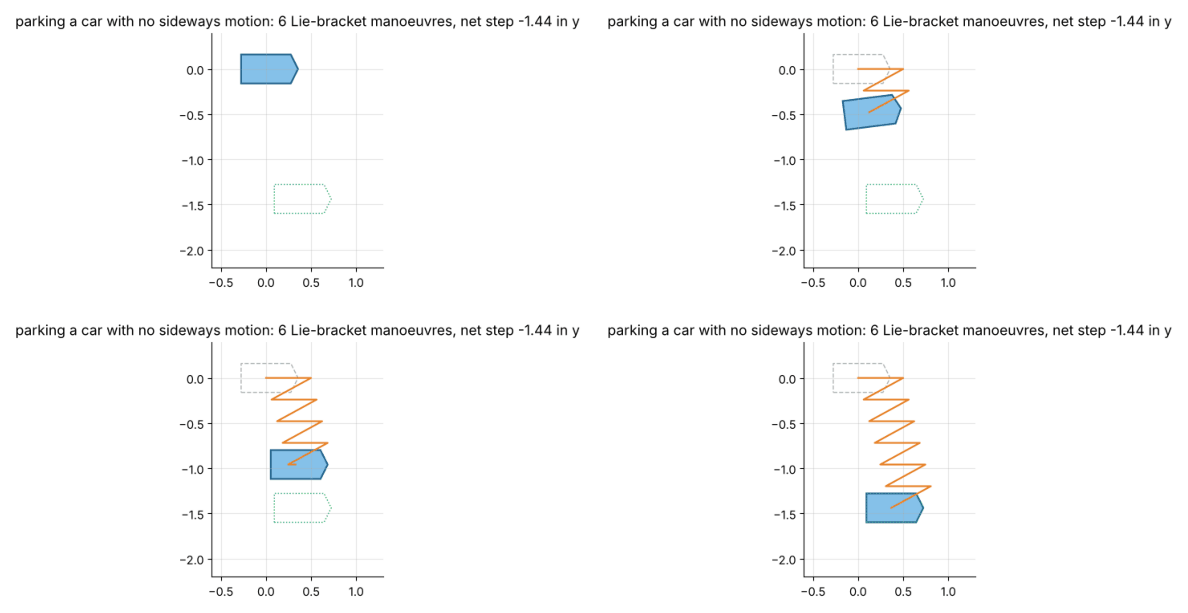

In [8]:
eps, reps = 0.5, 6
allp = [np.zeros(3)]
q = np.zeros(3)
for _ in range(reps):
    seg = cs.unicycle_path(q, [(1.0, 0.0, eps), (0.0, 1.0, eps), (-1.0, 0.0, eps), (0.0, -1.0, eps)], n_sub=12)
    allp.extend(seg[1:]); q = seg[-1]
allp = np.array(allp)
print(f"after {reps} manoeuvres: (x, y, theta) = ({allp[-1, 0]:.3f}, {allp[-1, 1]:.3f}, {allp[-1, 2]:.1e});  {reps} x single-step y = {reps * -eps * np.sin(eps):.3f}")
assert abs(allp[-1, 2]) < 1e-9 and abs(allp[-1, 1] - reps * (-eps * np.sin(eps))) < 1e-9

def car_outline(state, L=0.55, W=0.32):
    x, y, th = state
    body = np.array([[-L / 2, -W / 2], [L / 2, -W / 2], [L / 2 + 0.08, 0], [L / 2, W / 2], [-L / 2, W / 2]])
    Rm = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
    return body @ Rm.T + [x, y]

fig, ax = plt.subplots(figsize=(7.4, 3.8))
idx = np.linspace(0, len(allp) - 1, 41).astype(int)
def update(i):
    ax.cla(); k = idx[i]
    ax.plot(*allp[:k + 1, :2].T, "-", color="#e67e22", lw=1.5)
    ax.add_patch(plt.Polygon(car_outline(allp[0]), fc="none", ec="#aab7b8", ls="--"))
    ax.add_patch(plt.Polygon(car_outline(allp[k]), fc="#85c1e9", ec="#21618c", lw=1.5))
    ax.add_patch(plt.Polygon(car_outline(allp[-1]), fc="none", ec="#27ae60", ls=":"))
    ax.set_xlim(-0.6, 1.3); ax.set_ylim(-2.2, 0.4); ax.set_aspect("equal")
    ax.set_title(f"parking a car with no sideways motion: {reps} Lie-bracket manoeuvres, net step {allp[-1, 1]:.2f} in y")
animate(fig, update, range(len(idx)), interval=70, gif="assets/1.4-car-parallel-parking.gif", n_keyframes=4)

## 7. Worked examples

**Example 1.4.1 (dimensions).** Give the C-space and dimension of: a planar rigid body; a spatial rigid body; a UR5e with unlimited joints; a spherical pendulum.
*Solution.* $SE(2)=\mathbb R^2\times S^1$, dim 3; $SE(3)=\mathbb R^3\times SO(3)$, dim 6; $T^6$, dim 6; $S^2$, dim 2.

**Example 1.4.2 (shortest motion).** A wrist joint is at $350^\circ$ and must go to $10^\circ$. By how many degrees must it turn?
*Solution.* $\operatorname{wrap}(10^\circ-350^\circ) = \operatorname{wrap}(-340^\circ) = +20^\circ$, not $-340^\circ$.

**Example 1.4.3 (dimension of $SO(3)$).** A rotation matrix has 9 entries and satisfies $R^{\mathsf T}R=I$, six independent equations (the symmetric matrix has $3+2+1$ entries); $9-6=3$. A unit quaternion has
$4-1=3$ degrees of freedom. Both counts are confirmed by the rank computation of Section 3.

**Example 1.4.4 (a double cover).** The rotation of $360^\circ$ about any axis gives $R=I$ and the quaternion $q=-1$: two quaternions per rotation. Verified in Section 4.

**Example 1.4.5 (four-bar topology).** For the crank-rocker $(1,\,2.5,\,2,\,2.2)$, how many separate pieces does the C-space have, and what happens for a non-Grashof linkage?
*Solution.* The crank angle covers $360^\circ$ on both branches, which stay apart: **two** closed curves. For $(2,\,2.5,\,3,\,4)$ the crank angle covers only part of the circle and the branches join: **one** closed curve (Section 5).

**Example 1.4.6 (the car).** Show that the car's velocity constraint is non-holonomic. *Solution.* $\{g_1,g_2\}$ spans a 2-D space but with $[g_1,g_2]=(\sin\theta,-\cos\theta,0)$ the span is 3-D, so by Chow's theorem no $g(x,y,\theta)=0$ restricts the motion (Section 6).

**Example 1.4.7 (parking displacement).** The manoeuvre of step $\varepsilon = 0.2$ moves the car by $-\varepsilon\sin\varepsilon = -0.0397$ in $y$ (about $-\varepsilon^2 = -0.04$); six repetitions with $\varepsilon = 0.5$ move it $-1.438$ in $y$ (and $+0.367$ forward, because each repetition also gains $\varepsilon(1-\cos\varepsilon)=0.061$ along the heading). *Solution.* Computed in Section 6.

In [9]:
print("1.4.2  wrap(10° - 350°) =", np.degrees(cs.angle_diff(np.radians(350), np.radians(10))).round(6)); assert np.isclose(np.degrees(cs.angle_diff(np.radians(350), np.radians(10))), 20.0)
print("1.4.3  dims:", dims["SO(3)  {R^T R = I}  (9 numbers)"], dims["unit quaternions  {|q|^2=1}  (4 numbers)"])
print("1.4.5  rocker-angle gap check printed in Section 5.")
e = 0.2; f = cs.parking_manoeuvre(e)[-1]
print("1.4.7  eps = 0.2: y =", round(f[1], 4), "(−eps sin eps =", round(-e * np.sin(e), 4), ", −eps² =", -e ** 2, ") | six repetitions, eps = 0.5:", round(allp[-1, 1], 3))
assert abs(f[1] + 0.0397) < 1e-4 and abs(allp[-1, 1] + 1.438) < 1e-3 and abs(allp[-1, 0] - 0.367) < 1e-3

1.4.2  wrap(10° - 350°) = 20.0
1.4.3  dims: 3 3
1.4.5  rocker-angle gap check printed in Section 5.
1.4.7  eps = 0.2: y = -0.0397 (−eps sin eps = -0.0397 , −eps² = -0.04000000000000001 ) | six repetitions, eps = 0.5: -1.438


## 8. Summary

| Idea | Result |
|:--|:--|
| Configuration space | set of all configurations; dimension = DOF; **shape** matters |
| Circle, torus | $S^1$, $T^n$: angles wrap; differences are `wrap(q2 − q1)`; a straight joint motion wraps around the torus |
| Explicit vs implicit | explicit: $\dim\mathcal C$ coordinates, singular somewhere (Euler angles at $\beta=90^\circ$); implicit: more numbers plus constraints, no singularity; dimension $=n-\text{rank}$ |
| $SO(3)$ | ball of radius $\pi$ with antipodes identified $=S^3/\pm1$; quaternions double-cover; a $360^\circ$ loop is not contractible |
| Closed chain | C-space is a curve (or surface) in a torus; the four-bar has two components when crank-rocker, one when non-Grashof |
| Holonomic constraint | $g(q)=0$: reduces the dimension of C-space |
| Non-holonomic constraint | $A(q)\dot q=0$, non-integrable: restricts velocities, not reachable configurations (car, rolling disc); Lie brackets give the missing directions |

### Common mistakes

* Subtracting raw angles instead of using `wrap`; interpolating joint angles across the $\pm\pi$ seam.
* Believing that the dimension determines the shape: $T^2$ and $\mathbb R^2$ both have dimension 2.
* Adding quaternions or matrices to configurations as if they were vectors; use manifold-aware updates (`mj_integratePos`) or re-normalise.
* Calling every velocity constraint non-holonomic: *integrable* ones (the pendulum's) are holonomic in disguise.
* Expecting a four-bar that is assembled one way to reach the other assembly by moving — for a crank-rocker the two assemblies lie in different components of C-space.

## Exercises

**1.4.1** What is the C-space of a planar 3R arm with unlimited joints? Of a prismatic–revolute (PR) arm whose prismatic joint has range $[0, 1]$ m?

<details><summary>Answer</summary>

$T^3=S^1\times S^1\times S^1$ (dimension 3); $[0,1]\times S^1$, a finite cylinder (dimension 2).
</details>

**1.4.2** Two configurations of a 3R arm are $(170^\circ, -170^\circ, 10^\circ)$ and $(-170^\circ, 170^\circ, -10^\circ)$. Find the geodesic distance on the torus and the midpoint of the shortest interpolation.

<details><summary>Answer</summary>

Wrapped differences: $+20^\circ,\ -20^\circ,\ -20^\circ$; distance $=\sqrt{3}\cdot20^\circ = 34.64^\circ$. Midpoint $(180^\circ,\ -180^\circ,\ 0^\circ)$ (equivalently $(\pm180^\circ,\ \pm180^\circ,\ 0^\circ)$).
</details>

**1.4.3** Show that the rotation matrix of a rotation by $\pi$ about $\hat{\mathbf n}$ equals that about $-\hat{\mathbf n}$, and explain what this says about the ball model of $SO(3)$.

<details><summary>Answer</summary>

$R(\hat n,\pi)=2\hat n\hat n^{\mathsf T}-I$ is even in $\hat n$. The two rotation vectors $\pm\pi\hat n$ are antipodal points of the boundary sphere and give the same rotation: the boundary is glued antipodally.
</details>

**1.4.4** A $2$-link planar arm has joint limits $\theta_1\in[-110^\circ,110^\circ]$, $\theta_2\in[-150^\circ,150^\circ]$ (as the Dynamixel 2R). What is the C-space and what fraction of the torus does it cover?

<details><summary>Answer</summary>

A rectangle (a subset of the torus) of side $220^\circ\times300^\circ$, i.e. $\frac{220\cdot300}{360\cdot360} = 50.9\%$ of the torus.
</details>

**1.4.5** Decide whether the constraint $\dot x = \dot y$ (planar point, $q=(x,y)$) is holonomic.

<details><summary>Answer</summary>

Yes: $\dot x-\dot y=0$ integrates to $x-y=\text{const}$. The single free direction $(1,1)$ has no non-trivial brackets (the rank test of Section 6 returns 1).
</details>

**1.4.6** (*programming*) For the unicycle compute the Lie bracket $[g_1,g_2]$ at $\theta=\pi/2$ and say in which direction the car can be displaced at that heading.

<details><summary>Answer</summary>

$(\sin\theta,-\cos\theta,0)=(1,0,0)$: with the car pointing along $+y$, the bracket moves it along $+x$, sideways.
</details>

**1.4.7** (*MuJoCo*) Rotate the OP3's free base about $\hat Z$ at 1 rad/s for $2\pi$ s with `mj_integratePos`; what is the quaternion at the end, and what does this say about the double cover?

<details><summary>Answer</summary>

After one full turn the base orientation equals the original, but the quaternion is approximately $(-1,0,0,0)$ — the cover. The check cell below prints it.
</details>

In [10]:
# --- verification of the exercise answers ---
a_, b_ = np.radians([170, -170, 10]), np.radians([-170, 170, -10])
print("1.4.2  distance =", round(np.degrees(cs.torus_distance(a_, b_)), 2), "deg ; midpoint =", np.degrees(cs.torus_interpolate(a_, b_, 0.5)).round(1)); assert np.isclose(np.degrees(cs.torus_distance(a_, b_)), 34.64, atol=0.01)
n_ = np.array([0.3, -0.5, 0.8]); n_ /= np.linalg.norm(n_)
print("1.4.3  R(n, pi) == R(-n, pi):", np.allclose(tf.rot_axis_angle(n_, np.pi), tf.rot_axis_angle(-n_, np.pi)), "| 2 n n^T - I:", np.allclose(tf.rot_axis_angle(n_, np.pi), 2 * np.outer(n_, n_) - np.eye(3)))
print("1.4.4  fraction of the torus:", round(220 * 300 / (360 * 360) * 100, 1), "%")
print("1.4.5  rank:", cs.distribution_rank([lambda p: np.array([1.0, 1.0])], np.zeros(2), depth=3))
print("1.4.6  bracket at theta = pi/2:", cs.lie_bracket(cs.unicycle_field_g1, cs.unicycle_field_g2, np.array([0, 0, np.pi / 2])).round(4))
qa = mO.qpos0.copy(); qv = np.zeros(mO.nv); qv[5] = 1.0                       # angular velocity about z in the base frame
for _ in range(int(round(2 * np.pi / 0.001))): mujoco.mj_integratePos(mO, qa, qv, 0.001)
print("1.4.7  base quaternion after one full turn:", qa[3:7].round(3), "| residual angle:", round(2 * np.pi - int(round(2 * np.pi / 0.001)) * 0.001, 6))

1.4.2  distance = 34.64 deg ; midpoint = [180. 180.   0.]
1.4.3  R(n, pi) == R(-n, pi): True | 2 n n^T - I: True
1.4.4  fraction of the torus: 50.9 %
1.4.5  rank: 1
1.4.6  bracket at theta = pi/2: [1. 0. 0.]
1.4.7  base quaternion after one full turn: [-1.  0.  0.  0.] | residual angle: 0.000185


## Further reading and lectures

* Lynch & Park, §2.3–2.4 (topology, representation and constraints of C-space; the Pfaffian constraints and Chow's theorem are treated in Ch. 13 of the same book); Craig §2.8 on the three-parameter description of orientation; Siciliano et al., Ch. 1.
* Video: [Modern Robotics — 2.3.1 C-space topology](https://www.youtube.com/watch?v=FyLNR3edOds); [Modern Robotics — 2.3.2 C-space representation](https://www.youtube.com/watch?v=PPgJPjCUIXU); [Modern Robotics — 2.4 Configuration and velocity constraints](https://www.youtube.com/watch?v=A14ArEZ47LE).
* MuJoCo documentation on [`mj_integratePos`](https://mujoco.readthedocs.io/en/stable/APIreference/APIfunctions.html) and on free and ball joints.
* Next: Notebook 1.5 maps the joint space onto the space where the tool works — joint, actuator and task space, and the workspace.

---

[← 1.3 Degrees of Freedom and Grübler's Formula](1.3-degrees-of-freedom-and-grublers-formula.ipynb) &nbsp;·&nbsp; [Chapter contents](README.md) &nbsp;·&nbsp; [1.5 Spaces of a Robot and Its Workspace →](1.5-spaces-of-a-robot-and-its-workspace.ipynb)